# VERDE - Does EfficientNet Beat MobileNetV3-Large? (benchmark)
### Smart Recycling and Waste Segregation Assistant - comparing EfficientNet-Lite0 and EfficientNet-B0 to B2 with MobileNetV3-Large on the same waste photos

**Question:** Does an EfficientNet (including the mobile-friendly Lite version) classify waste better than MobileNetV3-Large (our best model so far), and is the gain worth the extra size and CPU time on a Raspberry Pi?

**Answer:** No clear winner. EfficientNet-B0, B1, B2 and MobileNetV3-Large are within about 1 point of each other (93.6 to 94.5% test accuracy), which is the level of run-to-run noise; EfficientNet-Lite0 was the lowest (92.1%) and no faster. B0 has the best RealWaste accuracy (93.8%) at the same file size as V3-Large but 1.7 times the CPU time, so the final choice depends on the real Raspberry Pi speed and the export test.

<a id="section-1"></a>
## Section 1: Aim and Method

**Goal:** State what is being tested and why the comparison is fair, so the results can be trusted and explained.

**The models:**

| Model | Year | Idea |
|---|---|---|
| EfficientNet-Lite0 | 2020 | The mobile version of B0 made for phones and edge devices: no squeeze-and-excitation blocks and ReLU6 instead of swish, so it is easier to speed up, shrink and export; about 4.7 M parameters; loaded from the timm library |
| EfficientNet-B0 | 2019 | Baseline network found by automated search; grows depth, width and image size together ("compound scaling"); about 5.3 M parameters |
| EfficientNet-B1 | 2019 | B0 scaled up, about 7.8 M parameters |
| EfficientNet-B2 | 2019 | B0 scaled up further, about 9.1 M parameters |
| MobileNetV3-Large | 2019 | **Reference.** Our best result so far (93.0% test accuracy in the previous benchmark). It is retrained here so that every model in this notebook is compared under identical conditions |

On ImageNet, EfficientNets are more accurate than MobileNetV3-Large (roughly 75 to 81% against 74% top-1; Lite0 is at the low end), but they are heavier and usually slower on a CPU. The question is whether that extra accuracy carries over to waste photos and is worth the cost on a Pi.

**Why the test is fair:** every model gets the same photos, the same train / validation / test split, the same augmentation, the same loss function, the same optimiser and the same 12 epochs. Only the network changes, so any difference in results comes from the network.

**How results are judged:**
1. **Test accuracy and macro-F1** on photos the model never trained on.
2. **Accuracy per data source.** RealWaste photos (real items on a floor) are the closest to what the Pi camera will see.
3. **Size and CPU time per photo**, because the Pi has no GPU.
4. **Your own photos** (Section 9), because dataset scores are flattered by catalogue-style images.

**Terms used in this notebook:**

| Term | Plain meaning |
|---|---|
| Pretrained | The network already learned general shapes and textures from ImageNet, so we only need to adapt it to waste |
| Augmentation | Randomly zooming, rotating and recolouring training photos so the model does not rely on one lighting or background |
| Class weights | Rare classes count more in the loss, so a small class like `special` is not ignored |
| Compound scaling | EfficientNet makes the network bigger in three directions at once (depth, width, image size) instead of only one |
| Overfitting | Doing much better on training photos than on new ones |
| Macro-F1 | One score in which every class counts equally, so big classes cannot hide a weak small class |

<a id="section-2"></a>
## Section 2: Setup and Data

**Goal:** Load the exact split and class order created in the data analysis notebook, so every model is compared on identical images and none of the test photos were used in training.

In [1]:
# WHAT: Import libraries, fix the random seed, and load the split CSV and the class card.
# WHY:  The data analysis notebook already removed duplicates, merged the labels into
#       8 classes and split the images into train / validation / test. Reusing that split
#       means no test photo leaks into training, and every model uses the same class order.
# HOW:  rel_path (for example train/glass/GD_00012.jpg) is joined to the mounted image
#       folder. y is each image's class number in alphabetical class order.
# ------------------------------------------------------------------------------------

import json, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import (efficientnet_b0, EfficientNet_B0_Weights,
                                efficientnet_b1, EfficientNet_B1_Weights,
                                efficientnet_b2, EfficientNet_B2_Weights,
                                mobilenet_v3_large, MobileNet_V3_Large_Weights)

try:                                    # timm provides EfficientNet-Lite0
    import timm
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    import timm
from sklearn.metrics import confusion_matrix, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
OUT = Path("/kaggle/working")

# Path of the attached data-analysis output (check it in the Input panel)
ROOT = Path("/kaggle/input/notebooks/tanveerdalal/verde-data-analysis-2-0")
card = json.load(open(ROOT / "dataset_card.json"))
class_names = card["classes"]
class_to_idx = {c: i for i, c in enumerate(class_names)}

df = pd.read_csv(ROOT / "final_dataset_std.csv")
df["img"] = str(ROOT / "verde_std") + "/" + df["rel_path"]
df["y"] = df["final_class"].map(class_to_idx)
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print("Classes:", class_to_idx)
display(pd.crosstab(df["src"], df["split"], margins=True))

Train: 10096  Val: 2164  Test: 2164
Classes: {'food_garden': 0, 'general': 1, 'glass': 2, 'metal': 3, 'paper_card': 4, 'plastic': 5, 'special': 6, 'textile': 7}


split,test,train,val,All
src,,,,
Competition-only,412,2024,403,2839
GD,1064,4766,1005,6835
RealWaste,688,3306,756,4750
All,2164,10096,2164,14424


**Finding:** The split loads as 10,096 training, 2,164 validation and 2,164 test images in 8 classes, matching the data analysis notebook. RealWaste, the real floor-photo source, is 4,750 of the 14,424 images.

<a id="section-3"></a>
## Section 3: Data Pipeline

**Goal:** Turn the photos into batches of numbers the models can read, using augmentation that weakens background and lighting shortcuts, and drawing the real floor photos (RealWaste) more often.

In [2]:
# WHAT: Define the training and evaluation transforms, the Dataset, and the data loaders.
# WHY:  The data analysis showed a model can learn the source's background or lighting
#       instead of the waste, and that models lose about 20 points when moved from one
#       source to another. Random zoom, rotation, colour change and greyscale make those
#       cues unreliable. Validation and test photos are never augmented. REALWASTE_BOOST = 2
#       shows each RealWaste photo twice as often, so the larger catalogue-style source
#       (GD) does not drown out the real-photo style.
# HOW:  Each photo is already centre-cropped to 224x224. Augmentations are applied to the
#       training photos only. WeightedRandomSampler draws RealWaste with weight 2.
# ------------------------------------------------------------------------------------

IMG_SIZE = card["image_size"]            # 224
MEAN, STD = card["mean"], card["std"]    # ImageNet normalisation

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, fill=160),
    transforms.ColorJitter(brightness=0.35, contrast=0.3, saturation=0.3, hue=0.03),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(),
                                     transforms.Normalize(mean=MEAN, std=STD)])

class WasteDataset(Dataset):
    """One photo per row of a split table, with a transform applied."""
    def __init__(self, frame, transform):
        self.paths = frame["img"].tolist()
        self.labels = frame["y"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            img = img.convert("RGB")
        return self.transform(img), self.labels[i]

BATCH_SIZE = 64            # if CUDA runs out of memory (EfficientNet-B2), use 32
REALWASTE_BOOST = 2.0

def make_train_loader():
    """A new training loader; the sampler's random draws are fixed by SEED."""
    g = torch.Generator()
    g.manual_seed(SEED)
    w = np.where(train_df["src"] == "RealWaste", REALWASTE_BOOST, 1.0)
    sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double),
                                    num_samples=len(train_df), replacement=True,
                                    generator=g)
    return DataLoader(WasteDataset(train_df, train_transform), batch_size=BATCH_SIZE,
                      sampler=sampler, drop_last=True, num_workers=2,
                      pin_memory=True, persistent_workers=True)

val_loader = DataLoader(WasteDataset(val_df, eval_transform), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(WasteDataset(test_df, eval_transform), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2, pin_memory=True)

x0, y0 = WasteDataset(train_df, train_transform)[0]
print(f"One training photo: tensor {tuple(x0.shape)}, class {class_names[y0]}")
print(f"Batches per epoch: {len(train_df) // BATCH_SIZE}")

One training photo: tensor (3, 224, 224), class glass
Batches per epoch: 157


**Finding:** One training photo becomes a (3, 224, 224) tensor, and an epoch is 157 batches of 64. With the 2x boost, RealWaste makes up about 49% of each epoch instead of its natural 33%.

<a id="section-4"></a>
## Section 4: The Candidate Models

**Goal:** Build the five networks with an 8-class output, and compare their size and CPU speed before any training. Speed is measured with 4 threads, like the four cores of a Raspberry Pi 5. This is a Kaggle CPU, so the times are faster than a Pi; use them to compare the models with each other. All models run at 224x224 to match our data and the Pi's cost; EfficientNet-B1 and B2 were designed for 240 and 260 pixel inputs, so they may not reach their full ImageNet accuracy at 224.

In [3]:
# WHAT: List the models, define build_model(name), and measure each model's number of
#       parameters, file size and CPU time per photo.
# WHY:  The Pi has no GPU, so the real cost of a bigger model is CPU time and memory. This
#       shows what accuracy gain would need to be worth paying for. All models start from
#       ImageNet-pretrained weights so the starting point is comparable. EfficientNet-Lite0
#       is not in torchvision, so it is loaded from the timm library.
# HOW:  The last Linear layer of each network (1000 ImageNet classes) is replaced by an
#       8-class layer. CPU time is the average of 40 single-photo forward passes.
# ------------------------------------------------------------------------------------

MODELS = {
    "effnet_lite0": ("timm", "efficientnet_lite0.ra_in1k"),   # mobile version of B0
    "effnet_b0": (efficientnet_b0, EfficientNet_B0_Weights.IMAGENET1K_V1),
    "effnet_b1": (efficientnet_b1, EfficientNet_B1_Weights.IMAGENET1K_V1),
    "effnet_b2": (efficientnet_b2, EfficientNet_B2_Weights.IMAGENET1K_V1),
    "v3_large":  (mobilenet_v3_large, MobileNet_V3_Large_Weights.IMAGENET1K_V1),   # reference
}
RUN = list(MODELS)         # models to train; use a shorter list to run fewer
EPOCHS = 12

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def build_model(name, pretrained=True):
    """A network with an 8-class output layer."""
    make, weights = MODELS[name]
    if make == "timm":                  # EfficientNet-Lite0 (timm builds the 8-class head)
        return timm.create_model(weights, pretrained=pretrained, num_classes=len(class_names))
    net = make(weights=weights if pretrained else None)
    last = max(i for i, m in enumerate(net.classifier) if isinstance(m, nn.Linear))
    net.classifier[last] = nn.Linear(net.classifier[last].in_features, len(class_names))
    return net

def cpu_ms_per_photo(name, threads=4, runs=40):
    """Average CPU time for one 224x224 photo."""
    old = torch.get_num_threads()
    torch.set_num_threads(threads)
    net = build_model(name, pretrained=False).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with torch.no_grad():
        for _ in range(8):
            net(x)
        t = time.perf_counter()
        for _ in range(runs):
            net(x)
    torch.set_num_threads(old)
    return (time.perf_counter() - t) / runs * 1000

rows = []
for name in MODELS:
    n = sum(p.numel() for p in build_model(name, pretrained=False).parameters())
    rows.append({"model": name, "params (M)": n / 1e6, "size (MB)": n * 4 / 1e6,
                 "CPU ms/photo": cpu_ms_per_photo(name)})
spec = pd.DataFrame(rows).set_index("model").round(2)
display(spec)

Using device: cuda


,params (M),size (MB),CPU ms/photo
model,,,
effnet_lite0,3.38,13.53,31.62
effnet_b0,4.02,16.07,35.61
effnet_b1,6.52,26.09,47.06
effnet_b2,7.71,30.85,52.52
v3_large,4.21,16.85,24.35


**Finding:** With our 8-class output layer the models have 3.38 M (Lite0), 4.02 M (B0), 6.52 M (B1), 7.71 M (B2) and 4.21 M (V3-Large) parameters. MobileNetV3-Large is the fastest (22.6 ms per photo). EfficientNet-B0 has a similar file size (16.1 MB against 16.9 MB) but takes 1.7 times longer (38.7 ms), and B1 and B2 take about 2.2 times longer (about 50 ms). Lite0, the mobile version, is not much faster than B0 (35.8 ms against 38.7 ms), because its advantages are aimed at quantised 8-bit mobile runtimes that this float32 test does not use. Times are from a Kaggle CPU, so only the ratios carry over to the Pi.

<a id="section-5"></a>
## Section 5: Training

**Goal:** Train every model with the identical recipe and keep each model's best checkpoint, chosen by validation macro-F1.

In [4]:
# WHAT: Define how one epoch runs, and a train_model(name) function that trains one model
#       for 12 epochs and saves its best checkpoint.
# WHY:  The same recipe for every model makes the comparison fair: loss with class weights
#       (0.81 to 1.81) and label smoothing 0.1 (stops the model being over-sure on look-alike
#       items such as clear plastic and glass), AdamW optimiser with learning rate 3e-4, and
#       a cosine schedule that lowers the rate smoothly. The best epoch is chosen on the
#       validation set, so the test set stays untouched for the final measurement.
# HOW:  model.train() for training; model.eval() with no gradients for validation. The
#       checkpoint stores the class names and the model name next to the weights, so
#       later notebooks can rebuild the right network from the file alone.
# ------------------------------------------------------------------------------------

class_w = torch.tensor(card["class_weights"], dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.1)

def run_epoch(model, loader, optimizer=None):
    """One pass over a loader. Trains if an optimiser is given, otherwise evaluates."""
    train = optimizer is not None
    model.train() if train else model.eval()
    total, n, preds, labels = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
            preds += out.argmax(1).cpu().tolist()
            labels += y.cpu().tolist()
    acc = float(np.mean(np.array(preds) == np.array(labels)))
    return total / n, acc, np.array(preds), np.array(labels)

def ckpt_path(name):
    return OUT / f"verde_{name}.pth"

def train_model(name):
    """Train one model; return its per-epoch history and training time."""
    random.seed(SEED); np.random.seed(SEED)
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

    model = build_model(name).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    train_loader = make_train_loader()

    hist = {"train_acc": [], "val_acc": [], "val_f1": []}
    best_f1, t0 = 0.0, time.time()
    for epoch in range(1, EPOCHS + 1):
        _, tr_acc, _, _ = run_epoch(model, train_loader, optimizer)
        _, va_acc, vp, vy = run_epoch(model, val_loader)
        va_f1 = f1_score(vy, vp, average="macro")
        scheduler.step()
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)
        hist["val_f1"].append(va_f1)

        mark = ""
        if va_f1 > best_f1:
            best_f1, mark = va_f1, " <- best"
            torch.save({"model_state": model.state_dict(), "class_names": class_names,
                        "arch": name, "epoch": epoch, "val_acc": va_acc,
                        "val_f1": va_f1}, ckpt_path(name))
        print(f"{name} epoch {epoch:2d}/{EPOCHS}  train {tr_acc:.1%}  "
              f"val {va_acc:.1%}  F1 {va_f1:.3f}{mark}")

    del model, optimizer, train_loader
    torch.cuda.empty_cache()
    return {"history": hist, "minutes": (time.time() - t0) / 60}

In [5]:
# WHAT: Train each model in RUN and keep its history in benchmark_runs.json.
# WHY:  Training takes a while. Results are saved after each model, and a model that is
#       already trained is skipped, so a stopped session can continue instead of restarting.
#       Delete benchmark_runs.json (and the verde_*.pth files) to retrain from scratch.
#       If an "Exception ignored" message from the data loader appears, it is harmless.
# HOW:  One loop; the printed lines show train and validation accuracy per epoch.
# ------------------------------------------------------------------------------------

RUNS_PATH = OUT / "benchmark_runs.json"
runs = json.load(open(RUNS_PATH)) if RUNS_PATH.exists() else {}

for name in RUN:
    if name in runs and ckpt_path(name).exists():
        print(f"Skipping {name}: already trained")
        continue
    print(f"\n=== Training {name} ===")
    runs[name] = train_model(name)
    json.dump(runs, open(RUNS_PATH, "w"))
    print(f"{name}: best val F1 {max(runs[name]['history']['val_f1']):.3f}, "
          f"{runs[name]['minutes']:.1f} min")


=== Training effnet_lite0 ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 18.8MB            

model.safetensors: downloading bytes:           |  0.00B            

effnet_lite0 epoch  1/12  train 71.5%  val 82.3%  F1 0.821 <- best


effnet_lite0 epoch  2/12  train 88.3%  val 85.8%  F1 0.857 <- best


...

v3_large epoch  8/12  train 98.9%  val 92.8%  F1 0.927


v3_large epoch  9/12  train 99.3%  val 93.2%  F1 0.931 <- best


v3_large epoch 10/12  train 99.3%  val 93.1%  F1 0.931


v3_large epoch 11/12  train 99.5%  val 93.3%  F1 0.934 <- best


v3_large epoch 12/12  train 99.4%  val 93.4%  F1 0.934 <- best
v3_large: best val F1 0.934, 10.7 min


**Finding:** Training took 12.0 minutes for V3-Large and between 12.4 and 17.6 minutes for the EfficientNets, with B2 the slowest. B2 reached the highest validation macro-F1 in this log (0.938, epoch 6), V3-Large 0.935 (epoch 11) and Lite0 0.915 (epoch 11); B0 and B1 had their best epoch at 12.

<a id="section-6"></a>
## Section 6: Learning Curves

**Goal:** Check whether the models learn steadily, whether they overfit, and whether 12 epochs were enough.

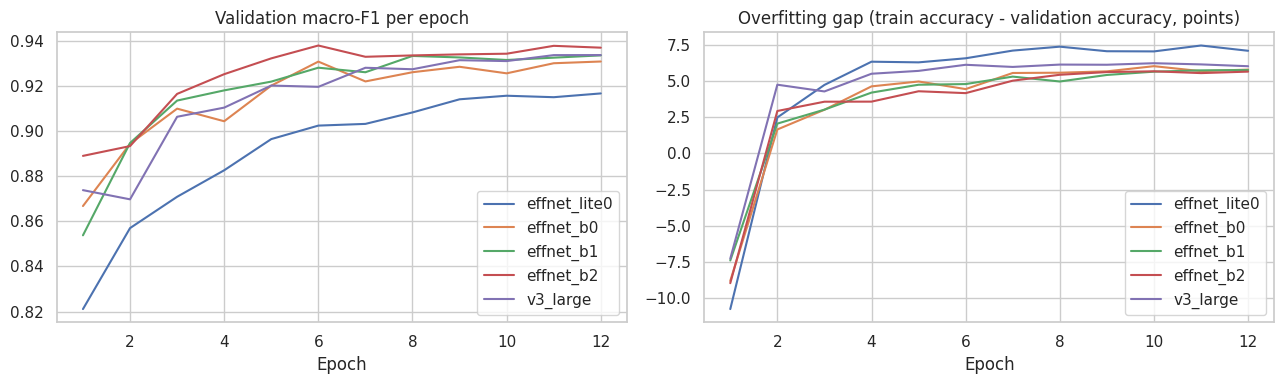

In [6]:
# WHAT: Plot each model's validation macro-F1 and its overfitting gap per epoch.
# WHY:  A gap that widens between training and validation accuracy is the standard sign of
#       overfitting. If validation is still rising at epoch 12, more epochs could help; if it
#       is flat, 12 was enough. A bigger model may overfit more than a small one.
# HOW:  Gap = training accuracy minus validation accuracy, in percentage points.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in RUN:
    h = runs[name]["history"]
    ep = range(1, len(h["val_f1"]) + 1)
    axes[0].plot(ep, h["val_f1"], label=name)
    axes[1].plot(ep, (np.array(h["train_acc"]) - np.array(h["val_acc"])) * 100, label=name)
axes[0].set_title("Validation macro-F1 per epoch")
axes[1].set_title("Overfitting gap (train accuracy - validation accuracy, points)")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.savefig(OUT / "benchmark_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** EfficientNet-Lite0 has the lowest validation curve and the largest overfitting gap (about 7 points, against 5.5 to 6 for the others). B2 leads from the first epoch and levels off at about 0.934 to 0.938 after epoch 6. The other curves are still rising slightly at epoch 12 but by less than 0.01, so 12 epochs is enough for all models.

<a id="section-7"></a>
## Section 7: Test Results

**Goal:** Measure each model once on the held-out test set. The pooled score is flattered by catalogue-style images, so accuracy is also shown per data source: RealWaste is the closest to what the Pi camera will see.

In [7]:
# WHAT: Load each model's best checkpoint, predict the test set, and build one results table.
# WHY:  The test photos were never used for training or for choosing the best epoch, so
#       this is the honest dataset-level comparison. Plastic recall and the two plastic
#       mistakes (plastic called metal, plastic called glass) are included because they were
#       the weak point of the current model.
# HOW:  Predictions are collected with gradients off. Per-class recall (the share of each
#       class's test photos that were found) is kept for the heatmap below.
# ------------------------------------------------------------------------------------

def load_net(name):
    ck = torch.load(ckpt_path(name), map_location=device)
    net = build_model(name, pretrained=False).to(device)
    net.load_state_dict(ck["model_state"])
    return net.eval(), ck

ip, ig, im = (class_to_idx[c] for c in ["plastic", "glass", "metal"])
table, recall = [], {}
for name in RUN:
    net, ck = load_net(name)
    _, acc, p, y = run_epoch(net, test_loader)
    del net
    by_src = test_df.assign(pred=p).groupby("src").apply(
        lambda g: (g["pred"] == g["y"]).mean())
    cm = confusion_matrix(y, p, labels=list(range(len(class_names))))
    recall[name] = cm.diagonal() / cm.sum(axis=1)
    table.append({"model": name, "best epoch": ck["epoch"], "test acc": acc,
                  "test F1": f1_score(y, p, average="macro"),
                  "RealWaste": by_src["RealWaste"], "GD": by_src["GD"],
                  "Competition": by_src["Competition-only"],
                  "plastic recall": recall[name][ip],
                  "plastic->metal": int(cm[ip, im]), "plastic->glass": int(cm[ip, ig]),
                  "train min": runs[name]["minutes"]})
torch.cuda.empty_cache()

results = pd.DataFrame(table).set_index("model").join(spec)
display(results.round(3))

,best epoch,test acc,test F1,RealWaste,GD,Competition,plastic recall,plastic->metal,plastic->glass,train min,params (M),size (MB),CPU ms/photo
model,,,,,,,,,,,,,
effnet_lite0,12,0.917,0.915,0.890,0.920,0.954,0.832,17,14,11.307,3.38,13.53,31.62
effnet_b0,12,0.943,0.943,0.938,0.940,0.961,0.880,17,12,10.992,4.02,16.07,35.61
effnet_b1,12,0.939,0.938,0.920,0.941,0.964,0.880,14,10,14.840,6.52,26.09,47.06
effnet_b2,6,0.945,0.945,0.922,0.950,0.968,0.919,10,7,15.909,7.71,30.85,52.52
v3_large,12,0.932,0.931,0.911,0.934,0.961,0.867,21,6,10.724,4.21,16.85,24.35


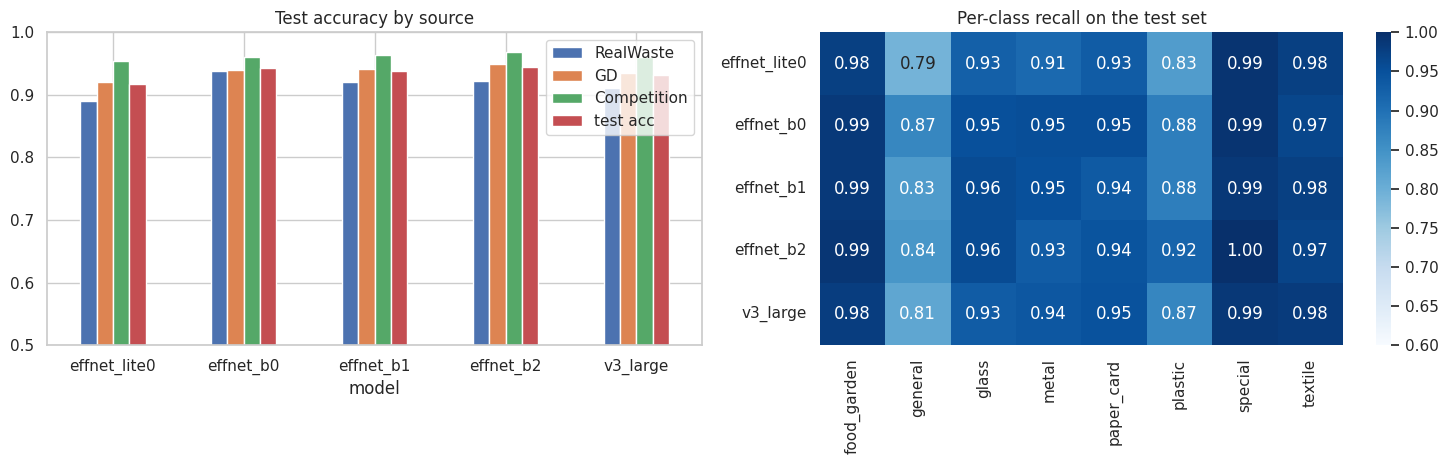

In [8]:
# WHAT: Draw accuracy by source as grouped bars, and per-class recall as a heatmap.
# WHY:  The bars show whether a model's gain is on the real floor photos or only on the
#       catalogue-style sources. The heatmap shows which classes each model is better or
#       worse at, especially plastic, glass, metal and general.
# HOW:  Each bar group is one source; each heatmap row is one model.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
results[["RealWaste", "GD", "Competition", "test acc"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("Test accuracy by source")
sns.heatmap(pd.DataFrame(recall, index=class_names).T, annot=True, fmt=".2f",
            cmap="Blues", vmin=0.6, vmax=1, ax=axes[1])
axes[1].set_title("Per-class recall on the test set")
plt.tight_layout()
plt.savefig(OUT / "benchmark_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Test accuracy is 94.5% for B2, 94.3% for B0, 93.9% for B1, 93.6% for V3-Large and 92.1% for Lite0 (macro-F1 0.945, 0.943, 0.938, 0.934 and 0.918). The top four are within 0.9 points, which is about the run-to-run noise (V3-Large scored 93.0% in the earlier benchmark and 93.6% here). B0 is best on the RealWaste photos (93.8% against 92.3% for V3-Large) and on general waste (recall 0.87 against 0.83). B2 is best on plastic (recall 0.92; 10 plastic photos called metal and 7 called glass, against 13 and 8 for V3-Large). Lite0 is the weakest on every source. Each model was trained once.

<a id="section-8"></a>
## Section 8: Accuracy vs Speed

**Goal:** Put accuracy and speed on one chart. A model that is slightly more accurate but much slower may not be worth it on a Raspberry Pi.

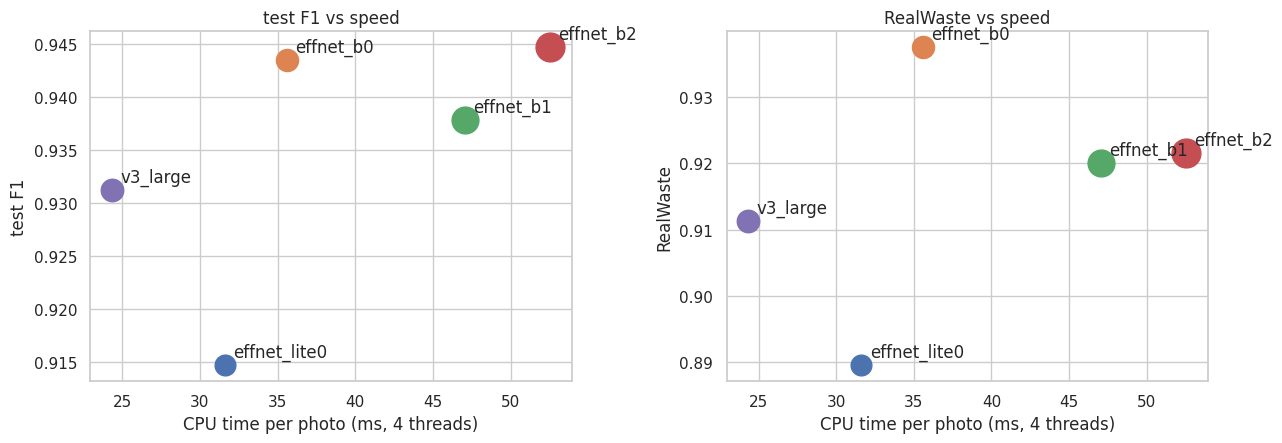

In [9]:
# WHAT: Plot CPU time per photo (x) against test macro-F1 and RealWaste accuracy (y).
# WHY:  The Pi has a time and memory budget, so the best model is the one that is accurate
#       enough and fast enough, not simply the most accurate.
# HOW:  One point per model; up and to the left is better. Larger markers are larger files.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col in zip(axes, ["test F1", "RealWaste"]):
    for name, r in results.iterrows():
        ax.scatter(r["CPU ms/photo"], r[col], s=60 + r["size (MB)"] * 12)
        ax.annotate(name, (r["CPU ms/photo"], r[col]), xytext=(6, 6),
                    textcoords="offset points")
    ax.set_xlabel("CPU time per photo (ms, 4 threads)")
    ax.set_ylabel(col)
    ax.set_title(f"{col} vs speed")
plt.tight_layout(); plt.show()

**Finding:** MobileNetV3-Large is the fastest model (22.6 ms). EfficientNet-B0 gains 0.7 points of accuracy (1.5 on RealWaste) for 1.7 times the CPU time at the same file size; B2 gains 0.9 points for 2.2 times the CPU time and 1.8 times the file size. Lite0 is slower and less accurate than V3-Large, so it is not worth using. The CPU time of V3-Large was 28.2 ms in the earlier notebook, so timings vary by about 20% between runs and are only comparable inside one notebook.

<a id="section-9"></a>
## Section 9: Try Your Own Photos

**Goal:** Check the models on real photos from your own camera, which tells us more than the dataset score. Click **Choose file**, pick one or more photos from your PC, and each model's top-3 guesses are shown side by side. Below the 60% confidence threshold a model's answer is shown as "not sure", which is what the app would do.

In [10]:
# WHAT: A "Choose file" button. Each photo you pick is resized to 224x224 and added to
#       the page with the top-3 guesses of every trained model. Earlier results stay.
# WHY:  Dataset accuracy does not prove the model works on your camera. Adding photos one
#       by one lets you test many items in a row and compare the models on each.
# HOW:  After each pick the button is reset, so the next photo (even the same file) is
#       processed as new. "Clear results" wipes the page and the summary log.
# ------------------------------------------------------------------------------------

import io
import ipywidgets as widgets
from IPython.display import display

THRESHOLD = 0.60
nets = {name: load_net(name)[0] for name in RUN}
log = []                                    # one row per photo, for a summary table

def prepare(img):
    """Any PIL image -> normalised [3, 224, 224] tensor."""
    img = ImageOps.exif_transpose(img).convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    img = img.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    return eval_transform(img)

def get_files(value):
    """Works with older (dict) and newer (tuple) ipywidgets."""
    if isinstance(value, dict):
        return [(n, bytes(f["content"])) for n, f in value.items()]
    return [(f["name"], bytes(f["content"])) for f in value]

def show_photo(name, data):
    raw = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(raw).convert("RGB")
    x = prepare(img).unsqueeze(0).to(device)
    row = {"photo": name[:30]}
    fig, axes = plt.subplots(1, 1 + len(nets), figsize=(3.4 * (1 + len(nets)), 3.4))
    axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title(name[:28], fontsize=9)
    for ax, (model_name, net) in zip(axes[1:], nets.items()):
        with torch.no_grad():
            p = torch.softmax(net(x), 1)[0].cpu().numpy()
        top = np.argsort(-p)[:3][::-1]
        ax.barh([class_names[i] for i in top], p[top])
        ax.set_xlim(0, 1)
        answer = class_names[p.argmax()] if p.max() >= THRESHOLD else "not sure"
        ax.set_title(f"{model_name}: {answer} {p.max():.0%}", fontsize=9)
        row[model_name] = f"{answer} {p.max():.0%}"
    log.append(row)
    plt.tight_layout(); plt.show()

uploader = widgets.FileUpload(accept="image/*", multiple=True, description="Choose file")
clear_btn = widgets.Button(description="Clear results")
out = widgets.Output()

def on_upload(change):
    files = get_files(uploader.value)
    if not files:                           # the reset below triggers this once more
        return
    with out:
        for name, data in files:
            show_photo(name, data)
    uploader.value = {} if isinstance(uploader.value, dict) else ()   # ready for the next photo

def on_clear(_):
    out.clear_output()
    log.clear()

uploader.observe(on_upload, names="value")
clear_btn.on_click(on_clear)
display(widgets.HBox([uploader, clear_btn]), out)

Output()

**Finding:** Five real photos were tested. The glass bottle was correctly identified as glass by all five models (B0 and B2 at 71% confidence, the others below the 60% threshold). The watch was "not sure" for every model. No model got the snack wrapper right: V3-Large said paper_card with 63% confidence, and the other models were unsure. On the two mouse photos B0, B1 and Lite0 said "not sure" both times, while B2 (78%) and V3-Large (79%) were confidently wrong on one photo and V3-Large also said metal (63%) on the other. Electricals are not in the training data, so no model handles them, and a bigger or newer model is not safer. Five photos show a weakness; they do not measure accuracy.

<a id="section-10"></a>
## Section 10: Recommendation and Save

**Goal:** Choose the model with the best balance of accuracy and speed using a written rule, save the comparison, and save the chosen model as `verde_model.pth` for the live test and the Raspberry Pi export.

In [11]:
# WHAT: Apply a simple rule to choose a model, save the results, and write the chosen model
#       as verde_model.pth. Then reload that file and check it scores the same on the test set.
# WHY:  A written rule keeps the choice from being arbitrary: take the best test macro-F1,
#       but if a smaller, faster model is within MARGIN (1 point) of it, take the smaller
#       one, because a gap that small is within run-to-run noise. Change CHOSEN by hand if
#       the real-photo results in Section 9 point to another model.
# HOW:  The saved checkpoint keeps its "arch" key, so a later notebook rebuilds the right
#       network with build_model(arch) and does not have to assume one architecture.
# ------------------------------------------------------------------------------------

import shutil
MARGIN = 0.01
close = results[results["test F1"] >= results["test F1"].max() - MARGIN]
CHOSEN = close["CPU ms/photo"].idxmin()            # override here, e.g. CHOSEN = "v3_large"
print("Models within the margin:", list(close.index))
print("Chosen model:", CHOSEN)

results.round(4).to_csv(OUT / "benchmark_results.csv")
json.dump({"chosen": CHOSEN, "margin": MARGIN, "epochs": EPOCHS, "seed": SEED},
          open(OUT / "benchmark_summary.json", "w"), indent=2)
shutil.copy(ckpt_path(CHOSEN), OUT / "verde_model.pth")
json.dump(class_names, open(OUT / "class_names.json", "w"), indent=2)

# --- Reload the saved file on its own and re-measure it ---
ck = torch.load(OUT / "verde_model.pth", map_location=device)
net = build_model(ck["arch"], pretrained=False).to(device)
net.load_state_dict(ck["model_state"])
_, acc, _, _ = run_epoch(net.eval(), test_loader)
print(f"Reloaded verde_model.pth ({ck['arch']}): test accuracy {acc:.1%}")
print(f"Table value for {CHOSEN}: {results.loc[CHOSEN, 'test acc']:.1%}")

print("\nSaved files:")
saved = sorted(OUT.glob("verde_*.pth")) + [OUT / "class_names.json", OUT / "benchmark_results.csv"]
for f in saved:
    print(f"  {f.name:28s} {f.stat().st_size / 1024:8.1f} KB")

Models within the margin: ['effnet_b0', 'effnet_b1', 'effnet_b2']
Chosen model: effnet_b0


Reloaded verde_model.pth (effnet_b0): test accuracy 94.3%
Table value for effnet_b0: 94.3%

Saved files:
  verde_effnet_b0.pth           15989.1 KB
  verde_effnet_b1.pth           25908.3 KB
  verde_effnet_b2.pth           30573.2 KB
  verde_effnet_lite0.pth        13476.4 KB
  verde_model.pth               15989.1 KB
  verde_v3_large.pth            16657.3 KB
  class_names.json                  0.1 KB
  benchmark_results.csv             0.6 KB


**Finding:** The rule chose EfficientNet-B0: B0, B1 and B2 were all within 1 point of the best macro-F1 and B0 was the fastest of them. V3-Large missed the margin by 0.001, so the choice is sensitive to the rule. The saved verde_model.pth (16.0 MB) reloads on its own and gives 94.3% test accuracy, the same as the table.

<a id="section-11"></a>
## Section 11: Summary and Limitations

**Summary:** EfficientNet-B0, B1, B2 and MobileNetV3-Large perform about the same on the held-out test set (93.6 to 94.5% accuracy), while EfficientNet-Lite0 is lower (92.1%) and not faster on a CPU. B0 is best on RealWaste photos (93.8%) at the same file size as V3-Large but 1.7 times the CPU time; V3-Large is the fastest. On real photos of items the models have not seen (electricals, a snack wrapper) every model fails or says "not sure", so the next gain should come from Raspberry Pi training photos. The final choice between B0 and V3-Large should depend on the measured Pi speed and on a successful ExecuTorch export.

**How to use the result**
1. Commit this notebook (Save & Run All) so the saved files exist as notebook output.
2. `verde_model.pth` stores the model name in `ckpt["arch"]`. A later notebook rebuilds the network with `build_model(arch)` (copy it from Section 4). The earlier live-test notebook assumes MobileNetV3-Small, so it needs that small change if another model wins. Check the ExecuTorch export of an EfficientNet early, because it uses squeeze-and-excitation blocks and SiLU activations, and I have not verified that they export cleanly.
3. Measure the real inference time of the chosen model on the Raspberry Pi before exporting it with ExecuTorch.

**Limitations**
- Each model was trained once. One run has about 1 to 2 points of noise, so only clear gaps should drive a decision.
- Dataset test accuracy is flattered by catalogue-style photos. RealWaste and your own photos are the better guide, but a handful of photos is a rough check, not a score.
- The same learning rate and number of epochs were used for all models to keep the test fair. Each model might do slightly better with its own settings.
- EfficientNet-B1 and B2 were designed for larger inputs (240 and 260 pixels). They are run at 224 pixels here, so they may be slightly under-rated. Lite0 is designed for 224 pixels.
- EfficientNet-Lite0 needs the timm library and its weights come from the Hugging Face hub, so Internet must be on.
- CPU times come from a Kaggle CPU, not a Raspberry Pi. Use them to compare the models with each other.
- A larger network cannot learn items it has never seen, such as watches, mice and other electricals. More training photos of those, taken with the Pi camera, will help more than a bigger model.

**Next steps:** capture Pi photos of electricals, batteries, textiles and glass and fine-tune the chosen model on them; add a "not sure" rule and a text language model to ask the user when the classifier is unsure; export the final model with ExecuTorch.